In [80]:
#Importamos las librerias
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import funciones_auxiliares_tp2
##QUIZAS EL GRAFICO DE BARRAS DE LA PROBA (1.a) PODRIA SER DE BASTONES
##CHEQUEAR LA ENTROPIA DE LA IMAGEN 2 POR RESIDUOS PORQUE AUMENTÓ

## Ejercicio 1:

### Inciso a

In [81]:
#Abrimos las imagenes, las pasamos a escala de grises y las convertimos en arrays
img_01=Image.open("./img_01.jpg").convert("L")
img_02=Image.open("./img_02.jpg").convert("L")
img_03=Image.open("./img_04.jpg").convert("L")
matriz_img1=np.array(img_01)
matriz_img2=np.array(img_02)
matriz_img3=np.array(img_03)

In [82]:
#Calculamos cuantas veces aparece cada intensidad en la imagen
frecuencias=[[0]*256 for i in range(3)]
matrices=[matriz_img1,matriz_img2,matriz_img3]
for i in range (3):
    for fila in matrices[i]:
        for pixel in fila:
            frecuencias[i][pixel]+=1
    frecuencias[i]=np.array(frecuencias[i])

#Una vez obtenidas las frecuencias calculamos las probabilidades
probas=[[0]*256 for i in range(3)]
for i in range(3):
    probas[i]=frecuencias[i]/matrices[i].size
    

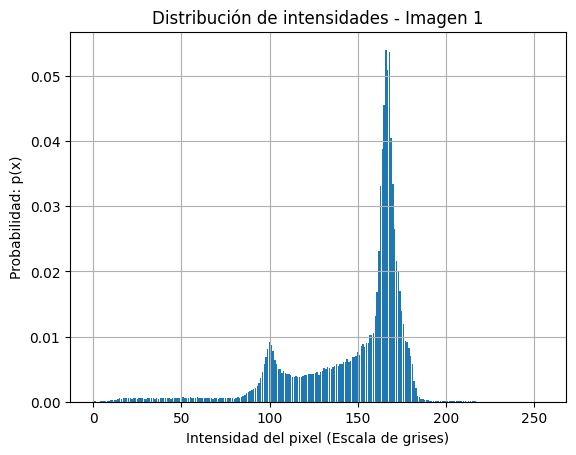

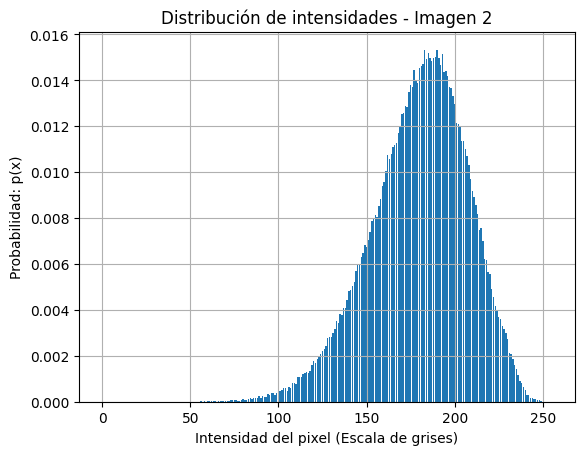

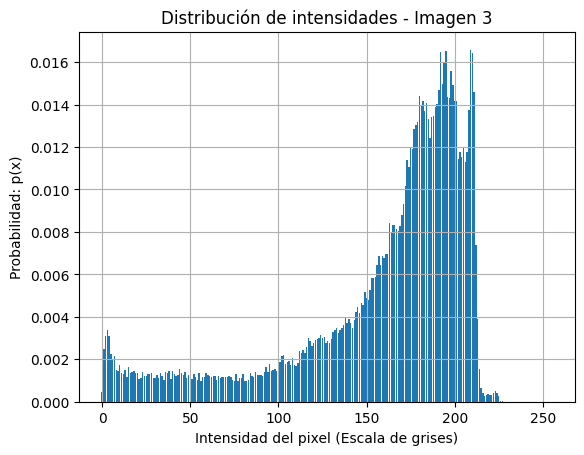

In [83]:
for i in range(3):
    plt.figure()
    plt.bar(range(256),probas[i])
    plt.xlabel("Intensidad del pixel (Escala de grises)")
    plt.ylabel("Probabilidad: p(x)")
    plt.title(f"Distribución de intensidades - Imagen {i+1}")
    plt.grid()
    plt.show()

Imagen 1: H(x)= 6.2809 bits/píxel
Imagen 2: H(x)= 6.7826 bits/píxel
Imagen 3: H(x)= 7.1377 bits/píxel


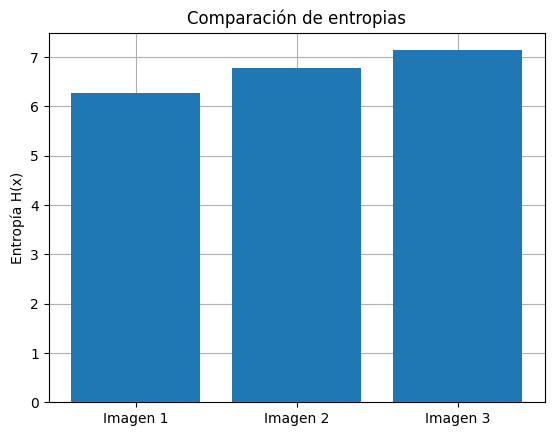

In [84]:
#Calculamos las entropías con las probabilidades obtenidas anteriormente
entropias=[0]*3
for i in range(3):
    suma=0
    for p in probas[i]:
        if p!=0:
            suma-=p*np.log2(p)
    entropias[i]=suma
    #Imprimimos las entropías
    print(f"Imagen {i+1}: H(x)= {entropias[i]:.4f} bits/píxel")

#Las mostramos en un gráfico para tener una representación más visual
plt.figure()
plt.bar(["Imagen 1","Imagen 2","Imagen 3"],entropias,zorder=3)
plt.grid(zorder=0)
plt.ylabel("Entropía H(x)")
plt.title("Comparación de entropias")
plt.show()

### Inciso b

In [85]:
#Armamos un diccionario con las probabilidades para poder pasarselo a lafuncion que codifica
probas_dict=[{} for i in range (3)]
for j in range(3):
    for i in range(256):
        if(probas[j][i]!=0):
            probas_dict[j][i]=probas[j][i]

In [86]:
compresion=[{} for i in range (3)]
largos_promedio=[0,0,0]

#Codificamos los valores y calculamos el largopromedio de los códigos de las intensidades
for i in range (3):
    suma=0
    compresion[i]=funciones_auxiliares_tp2.huffman_code(probas_dict[i])
    for intensidad,codigo in compresion[i].items():
        suma+=len(codigo)*frecuencias[i][intensidad]
    largos_promedio[i]=suma/matrices[i].size
    print(f"Imagen {i}: cantidad de bits promedio (por pixel) = {largos_promedio[i]}. Cota teórica: {entropias[i]} ≤ L < {entropias[i]+1}")

Imagen 0: cantidad de bits promedio (por pixel) = 6.309969190140845. Cota teórica: 6.280890879624666 ≤ L < 7.280890879624666
Imagen 1: cantidad de bits promedio (por pixel) = 6.8091959823144945. Cota teórica: 6.782600527294628 ≤ L < 7.782600527294628
Imagen 2: cantidad de bits promedio (por pixel) = 7.165109250221827. Cota teórica: 7.137708092292269 ≤ L < 8.137708092292268


## Ejercicio 2:

### Inciso a

In [87]:
#Calculamos los residuos (convertimos la matriz en int16 porque nos truncaba los negativos a cero)
residuos=[np.diff(matriz.astype(np.int16),axis=1) for matriz in matrices]
#Y guardamos los primeros pixeles de cada fila de cada imagen
primeros_pixeles=[matriz[:,0] for matriz in matrices]

In [88]:
probas_residuos=[{} for i in range(3)]
frecuencias_residuos=[[]for i in range(3)]
valores_residuos=[[]for i in range (3)]
for i  in range (3):
    valores_residuos[i],frecuencias_residuos[i]=np.unique(residuos[i],return_counts=True)
    for j in range (len(valores_residuos[i])):
        probas_residuos[i][valores_residuos[i][j]]=frecuencias_residuos[i][j]/residuos[i].size

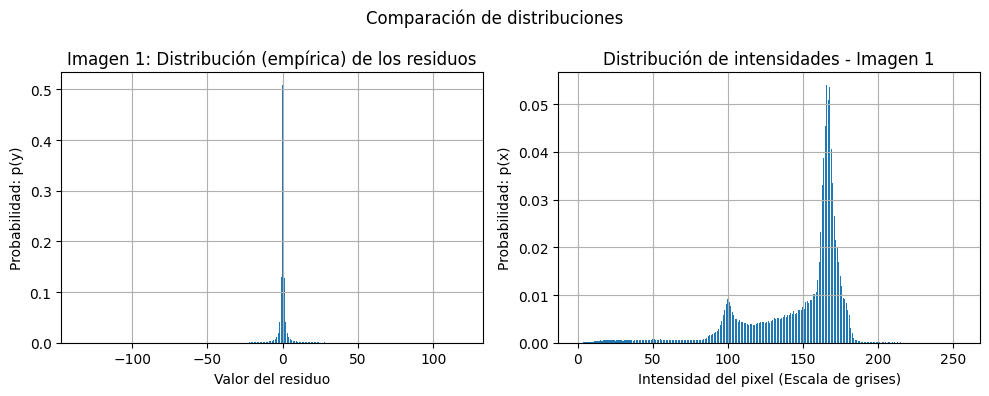

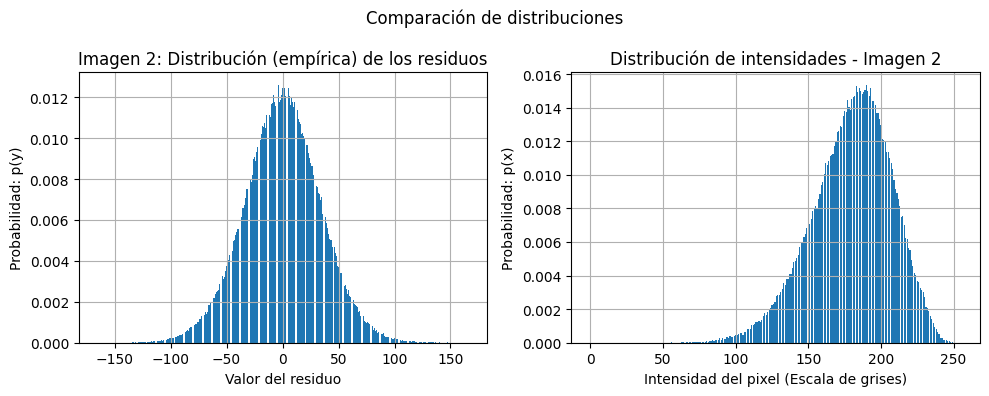

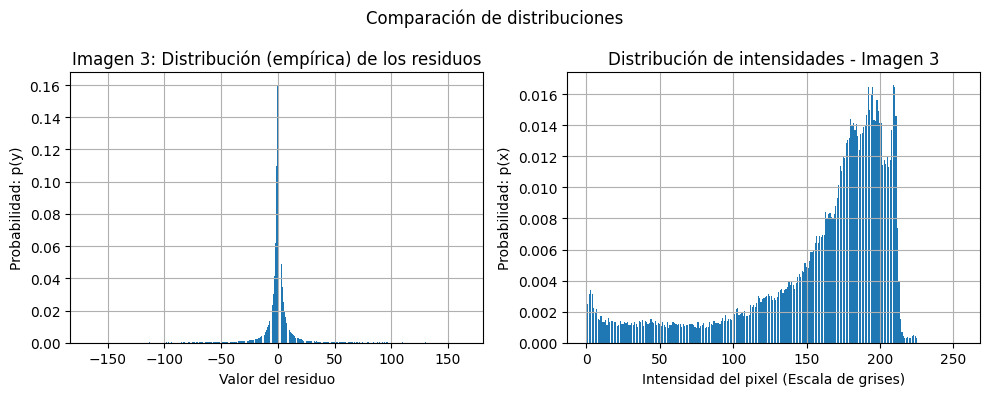

In [89]:
for i in range(3):
    fig,(ax1,ax2)=plt.subplots(1,2,figsize=(10,4))
    ax1.bar(list(probas_residuos[i].keys()), list(probas_residuos[i].values()))
    ax1.set_xlabel("Valor del residuo")
    ax1.set_ylabel("Probabilidad: p(y)")
    ax1.set_title(f"Imagen {i+1}: Distribución (empírica) de los residuos")
    ax1.grid()
    ax2.bar(range(256),probas[i])
    ax2.set_xlabel("Intensidad del pixel (Escala de grises)")
    ax2.set_ylabel("Probabilidad: p(x)")
    ax2.set_title(f"Distribución de intensidades - Imagen {i+1}")
    ax2.grid() 
    fig.suptitle("Comparación de distribuciones")
    plt.tight_layout()
    plt.show()

In [90]:
entropias_residuos=[0,0,0]
for i in range(3):
    suma=0
    for proba in probas_residuos[i].values():
        suma-=proba*np.log2(proba)
    entropias_residuos[i]=suma
    print(f"Imagen {i+1}: H(y)={entropias_residuos[i]}")
## Fltaria terminar la comparación

Imagen 1: H(y)=2.8237520541333905
Imagen 2: H(y)=7.138031018068324
Imagen 3: H(y)=4.863459160015615


### Inciso b

In [91]:
compresion_residuos=[{} for i in range (3)]
largos_promedio_residuos=[0,0,0]
for i in range(3):
    suma=0
    compresion_residuos[i]=funciones_auxiliares_tp2.huffman_code(probas_residuos[i])
    for intensidad,codigo in compresion_residuos[i].items():
        suma+=len(codigo)*probas_residuos[i][intensidad]
    largos_promedio_residuos[i]=suma
    print(f"Imagen {i}: cantidad de bits promedio (por pixel) al codificar los residuos = {largos_promedio_residuos[i]}. Cota teórica: {entropias_residuos[i]} ≤ L < {entropias_residuos[i]+1}")

Imagen 0: cantidad de bits promedio (por pixel) al codificar los residuos = 2.8378747795414476. Cota teórica: 2.8237520541333905 ≤ L < 3.8237520541333905
Imagen 1: cantidad de bits promedio (por pixel) al codificar los residuos = 7.178680883155224. Cota teórica: 7.138031018068324 ≤ L < 8.138031018068325
Imagen 2: cantidad de bits promedio (por pixel) al codificar los residuos = 4.888740542946145. Cota teórica: 4.863459160015615 ≤ L < 5.863459160015615
